In [2]:
## Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
## load the FragPipe protein table
protein_file = "../results/fragpipe_lfq_mbr/combined_protein.tsv"

df = pd.read_csv(protein_file, sep="\t")

print(df.shape)
df.head()

(8181, 45)


,Protein,Protein ID,Entry Name,Gene,Protein Length,Organism,Protein Existence,Description,Protein Probability,Top Peptide Probability,...,4 Intensity,5 Intensity,6 Intensity,1 MaxLFQ Intensity,2 MaxLFQ Intensity,3 MaxLFQ Intensity,4 MaxLFQ Intensity,5 MaxLFQ Intensity,6 MaxLFQ Intensity,Indistinguishable Proteins
0,contam_sp|P00004|CYC_HORSE,P00004,CYC_HORSE,CYCS,105,Equus caballus,1:Experimental evidence at protein level,Cytochrome c,1.0000,0.9990,...,2.468856e+07,1.960814e+07,0.000000e+00,2.628529e+07,0.000000e+00,2.058333e+07,2.468856e+07,1.960814e+07,0.000000e+00,NaN
1,contam_sp|P00366|DHE3_BOVIN,P00366,DHE3_BOVIN,GLUD1,558,Bos taurus,1:Experimental evidence at protein level,"Glutamate dehydrogenase 1, mitochondrial",1.0000,0.9990,...,1.557458e+08,6.561798e+07,2.014683e+08,0.000000e+00,0.000000e+00,0.000000e+00,7.896767e+07,3.531538e+07,1.088503e+08,NaN
2,contam_sp|P00761|TRYP_PIG,P00761,TRYP_PIG,NaN,231,Sus scrofa,1:Experimental evidence at protein level,Trypsin,1.0000,0.9990,...,1.299732e+10,1.929343e+10,1.580451e+10,1.008189e+10,5.638731e+09,1.076065e+10,7.557214e+09,9.810428e+09,8.518268e+09,NaN
3,contam_sp|P02769|ALBU_BOVIN,P02769,ALBU_BOVIN,ALB,607,Bos taurus,1:Experimental evidence at protein level,Albumin,1.0000,0.9990,...,5.823825e+08,5.069096e+08,1.004692e+09,2.981729e+08,2.115689e+08,5.400273e+08,4.500087e+08,1.965361e+08,3.564004e+08,NaN
4,contam_sp|P15241|K2M2_SHEEP,P15241,K2M2_SHEEP,NaN,491,Ovis aries,1:Experimental evidence at protein level,"Keratin, type II microfibrillar, component 7C",0.9868,0.9989,...,0.000000e+00,1.200723e+08,2.190978e+08,0.000000e+00,9.838455e+07,6.329854e+07,0.000000e+00,1.200723e+08,2.190978e+08,"contam_sp|P25691|K2M3_SHEEP, sp|O43790|KRT86_H..."


In [4]:
## Create a table that describes our 6 samples
sample_info = pd.DataFrame({
    "sample": ["WT-1", "WT-2", "WT-3", "MUT-1", "MUT-2", "MUT-3"], 
    "condition": ["IDHwt","IDHwt","IDHwt","IDHmut","IDHmut","IDHmut"],
    
    # Exact column names from the FragPipe protein table
    "column": ["1 MaxLFQ Intensity", "2 MaxLFQ Intensity", "3 MaxLFQ Intensity", "4 MaxLFQ Intensity", "5 MaxLFQ Intensity","6 MaxLFQ Intensity"]
})

#show the table
sample_info


,sample,condition,column
0,WT-1,IDHwt,1 MaxLFQ Intensity
1,WT-2,IDHwt,2 MaxLFQ Intensity
2,WT-3,IDHwt,3 MaxLFQ Intensity
3,MUT-1,IDHmut,4 MaxLFQ Intensity
4,MUT-2,IDHmut,5 MaxLFQ Intensity
5,MUT-3,IDHmut,6 MaxLFQ Intensity


In [6]:
sample_info["condition"]

0     IDHwt
1     IDHwt
2     IDHwt
3    IDHmut
4    IDHmut
5    IDHmut
Name: condition, dtype: object

In [14]:
# Get the exact FRagPipe LFQ column names
maxlfq_cols = sample_info["column"].tolist()

In [15]:
sample_info["column"]

0    1 MaxLFQ Intensity
1    2 MaxLFQ Intensity
2    3 MaxLFQ Intensity
3    4 MaxLFQ Intensity
4    5 MaxLFQ Intensity
5    6 MaxLFQ Intensity
Name: column, dtype: object

In [16]:
# Select only the six MaxLFQ columns from the full FragPipe table
quant = df[maxlfq_cols].copy()

# Give the columns easier sample names
quant.columns = sample_info["sample"]

# Show the first five proteins
quant.head()

sample,WT-1,WT-2,WT-3,MUT-1,MUT-2,MUT-3
0,2.628529e+07,0.000000e+00,2.058333e+07,2.468856e+07,1.960814e+07,0.000000e+00
1,0.000000e+00,0.000000e+00,0.000000e+00,7.896767e+07,3.531538e+07,1.088503e+08
2,1.008189e+10,5.638731e+09,1.076065e+10,7.557214e+09,9.810428e+09,8.518268e+09
3,2.981729e+08,2.115689e+08,5.400273e+08,4.500087e+08,1.965361e+08,3.564004e+08
4,0.000000e+00,9.838455e+07,6.329854e+07,0.000000e+00,1.200723e+08,2.190978e+08


In [17]:
quant.shape

(8181, 6)

In [18]:
quant.head

<bound method NDFrame.head of sample          WT-1          WT-2          WT-3         MUT-1         MUT-2  \
0       2.628529e+07  0.000000e+00  2.058333e+07  2.468856e+07  1.960814e+07   
1       0.000000e+00  0.000000e+00  0.000000e+00  7.896767e+07  3.531538e+07   
2       1.008189e+10  5.638731e+09  1.076065e+10  7.557214e+09  9.810428e+09   
3       2.981729e+08  2.115689e+08  5.400273e+08  4.500087e+08  1.965361e+08   
4       0.000000e+00  9.838455e+07  6.329854e+07  0.000000e+00  1.200723e+08   
...              ...           ...           ...           ...           ...   
8176    0.000000e+00  3.997477e+07  2.369341e+07  3.266048e+07  5.418346e+07   
8177    0.000000e+00  0.000000e+00  0.000000e+00  1.201864e+07  1.378439e+07   
8178    1.892761e+07  2.235935e+07  0.000000e+00  0.000000e+00  0.000000e+00   
8179    1.449841e+08  1.091828e+08  1.000646e+08  3.086855e+07  6.377696e+07   
8180    0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00   

sample   

In [19]:
quant.iloc[0]

sample
WT-1     26285286.0
WT-2            0.0
WT-3     20583328.0
MUT-1    24688556.0
MUT-2    19608138.0
MUT-3           0.0
Name: 0, dtype: float64

In [20]:
# Identify contaminant proteins
# FragPipe contaminant proteins start with "contam_"
is_contaminant = df["Protein"].str.startswith("contam_", na=False)

# Count how many contaminants there are
print("Contaminants:", is_contaminant.sum())

Contaminants: 6


In [21]:
# Keep only proteins that are NOT contaminants
df_clean = df.loc[~is_contaminant].copy()

print("Proteins before cleaning:", len(df))
print("Proteins after contaminant removal:", len(df_clean))

Proteins before cleaning: 8181
Proteins after contaminant removal: 8175


In [22]:
df_clean.shape

(8175, 45)

In [23]:
## apply the 2-of-3 replicate filter
## Now we remove proteins that are too sparsely detected.
## Our rule is: Keep a protein if it is detected in at least 2 of 3 replicates in either IDHwt or IDHmut.
# First define the WT and MUT MaxLFQ columns
# MaxLFQ columns for the three WT replicates
wt_cols = [
    "1 MaxLFQ Intensity",
    "2 MaxLFQ Intensity",
    "3 MaxLFQ Intensity"
]

# MaxLFQ columns for the three mutant replicates
mut_cols = [
    "4 MaxLFQ Intensity",
    "5 MaxLFQ Intensity",
    "6 MaxLFQ Intensity"
]

In [24]:
# Count how many WT replicates contain a measurable value
wt_count = (df_clean[wt_cols] > 0).sum(axis=1)

# Count how many MUT replicates contain a measurable value
mut_count = (df_clean[mut_cols] > 0).sum(axis=1)

In [25]:
# Protein must be present in at least 2 WT replicates
# OR at least 2 MUT replicates

keep = (wt_count >= 2) | (mut_count >= 2)

In [26]:
df_filtered = df_clean.loc[keep].copy()

print("Proteins before replicate filtering:", len(df_clean))
print("Proteins retained:", len(df_filtered))
print("Proteins removed:", len(df_clean) - len(df_filtered))

Proteins before replicate filtering: 8175
Proteins retained: 6233
Proteins removed: 1942


In [27]:
# build the final quantitative matrix
# Now create a matrix containing only the 6 MaxLFQ columns from the filtered proteins:
# Select only the six MaxLFQ columns
quant_filtered = df_filtered[maxlfq_cols].copy()

# Rename the columns to easy sample names
quant_filtered.columns = sample_info["sample"]

# Check the size
quant_filtered.shape

(6233, 6)

In [28]:
quant_filtered.head()

sample,WT-1,WT-2,WT-3,MUT-1,MUT-2,MUT-3
6,0.0,0.0,0.0,8114585.0,0.0,5414814.5
7,0.0,1764891.5,16501871.0,0.0,0.0,0.0
8,0.0,42507476.0,53974724.0,0.0,0.0,0.0
12,38038770.0,87556296.0,0.0,33656680.0,0.0,14787155.0
13,0.0,149968750.0,249465310.0,165669520.0,164623360.0,44899684.0


In [29]:
# Keep useful protein information
protein_info = df_filtered[
    ["Protein", "Protein ID", "Gene", "Description"]
].copy()

protein_info.head()

,Protein,Protein ID,Gene,Description
6,sp|A0A024RBG1|NUD4B_HUMAN,A0A024RBG1,NUDT4B,Diphosphoinositol polyphosphate phosphohydrola...
7,sp|A0A075B6H9|LV469_HUMAN,A0A075B6H9,IGLV4-69,Immunoglobulin lambda variable 4-69
8,sp|A0A075B6I0|LV861_HUMAN,A0A075B6I0,IGLV8-61,Immunoglobulin lambda variable 8-61
12,sp|A0A075B6K4|LV310_HUMAN,A0A075B6K4,IGLV3-10,Immunoglobulin lambda variable 3-10
13,sp|A0A075B6K5|LV39_HUMAN,A0A075B6K5,IGLV3-9,Immunoglobulin lambda variable 3-9


In [30]:
print("Protein information:", protein_info.shape)
print("Quantitative matrix:", quant_filtered.shape)

Protein information: (6233, 4)
Quantitative matrix: (6233, 6)


In [31]:
## Missing values + log2 transformation.
# Make a copy so we do not change the original matrix
quant_work = quant_filtered.copy()

quant_work.shape

(6233, 6)

In [32]:
# Convert zeros to missing values
# Replace zero intensities with NaN
quant_work = quant_work.replace(0, np.nan)

quant_work.head()

sample,WT-1,WT-2,WT-3,MUT-1,MUT-2,MUT-3
6,NaN,NaN,NaN,8114585.0,NaN,5414814.5
7,NaN,1764891.5,16501871.0,NaN,NaN,NaN
8,NaN,42507476.0,53974724.0,NaN,NaN,NaN
12,38038770.0,87556296.0,NaN,33656680.0,NaN,14787155.0
13,NaN,149968750.0,249465310.0,165669520.0,164623360.0,44899684.0


In [33]:
# Count missing values in each sample
missing_count = quant_work.isna().sum()

missing_count

sample
WT-1      907
WT-2      892
WT-3     1134
MUT-1    1255
MUT-2     964
MUT-3    1413
dtype: int64

In [34]:
missing_percent = quant_work.isna().mean() * 100

missing_percent.round(1)

sample
WT-1     14.6
WT-2     14.3
WT-3     18.2
MUT-1    20.1
MUT-2    15.5
MUT-3    22.7
dtype: float64

In [35]:
# Log2 transform measured MaxLFQ intensities
log2_quant = np.log2(quant_work)

log2_quant.head()

sample,WT-1,WT-2,WT-3,MUT-1,MUT-2,MUT-3
6,NaN,NaN,NaN,22.952086,NaN,22.368480
7,NaN,20.751148,23.976126,NaN,NaN,NaN
8,NaN,25.341213,25.685781,NaN,NaN,NaN
12,25.180967,26.383708,NaN,25.004390,NaN,23.817841
13,NaN,27.160087,27.894264,27.303733,27.294594,25.420202


In [36]:
# Check the transformed matrix
print("Raw filtered matrix:", quant_filtered.shape)
print("Log2 matrix:", log2_quant.shape)

log2_quant.describe()

Raw filtered matrix: (6233, 6)
Log2 matrix: (6233, 6)


sample,WT-1,WT-2,WT-3,MUT-1,MUT-2,MUT-3
count,5326.000000,5341.000000,5099.000000,4978.000000,5269.000000,4820.000000
mean,26.380862,26.170102,26.303981,26.379108,26.261697,26.385143
std,1.927682,1.943243,1.970161,2.066653,2.086650,2.055977
min,20.049479,20.124810,18.901977,19.947007,20.037186,19.916381
25%,24.970236,24.757224,24.915212,24.936308,24.754903,24.917798
50%,26.089674,25.877876,25.992988,26.114651,25.980042,26.108912
75%,27.568253,27.373552,27.505506,27.625432,27.496214,27.608656
max,34.400518,34.061452,34.481660,35.023860,34.103229,34.821814


In [37]:
# Find proteins with a measured value in ALL 6 samples
complete_mask = log2_quant.notna().all(axis=1)

# Keep only those proteins
log2_complete = log2_quant.loc[complete_mask].copy()

print("Filtered proteins:", len(log2_quant))
print("Complete in all 6 samples:", len(log2_complete))
print(
    "Percentage complete:",
    round(len(log2_complete) / len(log2_quant) * 100, 1),
    "%"
)

Filtered proteins: 6233
Complete in all 6 samples: 3518
Percentage complete: 56.4 %


In [38]:
#verify and save the processed data
#Before moving to PCA, we want to make sure log2_complete contains no missing values
# Count ALL missing values in the complete-case matrix
total_missing = log2_complete.isna().sum().sum()

print("Missing values in complete matrix:", total_missing)
print("Matrix shape:", log2_complete.shape)

Missing values in complete matrix: 0
Matrix shape: (3518, 6)


In [39]:
from pathlib import Path

# Folder for processed data
processed_dir = Path("../results/processed")

# Create it if it does not already exist
processed_dir.mkdir(parents=True, exist_ok=True)

In [40]:
sample_info.to_csv(
    processed_dir / "sample_metadata.csv",
    index=False
)

In [41]:
log2_quant.to_csv(
    processed_dir / "log2_maxlfq_filtered.csv"
)

In [42]:
log2_complete.to_csv(
    processed_dir / "log2_maxlfq_complete.csv"
)

In [43]:
protein_info.to_csv(
    processed_dir / "filtered_protein_metadata.csv",
    index=True
)

## PCA of the proteomics data
* Today we ask a different question from correlation:
* Without telling the algorithm which samples are WT or MUT, do the six samples naturally separate based on their protein-abundance profiles?

* That is what Principal Component Analysis (PCA) helps us examine.

In [44]:
# Transpose the matrix so that:
# rows    = samples
# columns = proteins

pca_input = log2_complete.T

print("Original matrix:", log2_complete.shape)
print("PCA input matrix:", pca_input.shape)

Original matrix: (3518, 6)
PCA input matrix: (6, 3518)


In [45]:
from sklearn.decomposition import PCA

In [46]:
# Ask PCA to calculate the first two principal components
pca = PCA(n_components=2)

In [47]:
pca_scores = pca.fit_transform(pca_input)

In [48]:
print("PCA scores shape:", pca_scores.shape)
print(pca_scores)

PCA scores shape: (6, 2)
[[ 2.62848358e+01 -2.67151727e+01]
 [ 3.23268988e+01  1.35423873e+01]
 [ 3.49811111e+01  1.06705198e+01]
 [-2.60151835e+01 -1.38737013e-02]
 [-3.03961883e+01 -2.30694097e+00]
 [-3.71814739e+01  4.82308029e+00]]


In [49]:
explained = pca.explained_variance_ratio_ * 100

print("PC1 explains:", round(explained[0], 1), "%")
print("PC2 explains:", round(explained[1], 1), "%")
print("PC1 + PC2:", round(explained.sum(), 1), "%")

PC1 explains: 66.4 %
PC2 explains: 11.6 %
PC1 + PC2: 78.0 %


In [50]:
# Convert the PCA coordinates into a readable table
pca_df = pd.DataFrame(
    pca_scores,
    columns=["PC1", "PC2"],
    index=pca_input.index
)

pca_df

,PC1,PC2
sample,,
WT-1,26.284836,-26.715173
WT-2,32.326899,13.542387
WT-3,34.981111,10.670520
MUT-1,-26.015184,-0.013874
MUT-2,-30.396188,-2.306941
MUT-3,-37.181474,4.823080


In [51]:
# Create a dictionary linking sample names to conditions
condition_map = {
    "WT-1": "IDHwt",
    "WT-2": "IDHwt",
    "WT-3": "IDHwt",
    "MUT-1": "IDHmut",
    "MUT-2": "IDHmut",
    "MUT-3": "IDHmut"
}

# Add condition information to the PCA table
pca_df["Condition"] = pca_df.index.map(condition_map)

pca_df

,PC1,PC2,Condition
sample,,,
WT-1,26.284836,-26.715173,IDHwt
WT-2,32.326899,13.542387,IDHwt
WT-3,34.981111,10.670520,IDHwt
MUT-1,-26.015184,-0.013874,IDHmut
MUT-2,-30.396188,-2.306941,IDHmut
MUT-3,-37.181474,4.823080,IDHmut


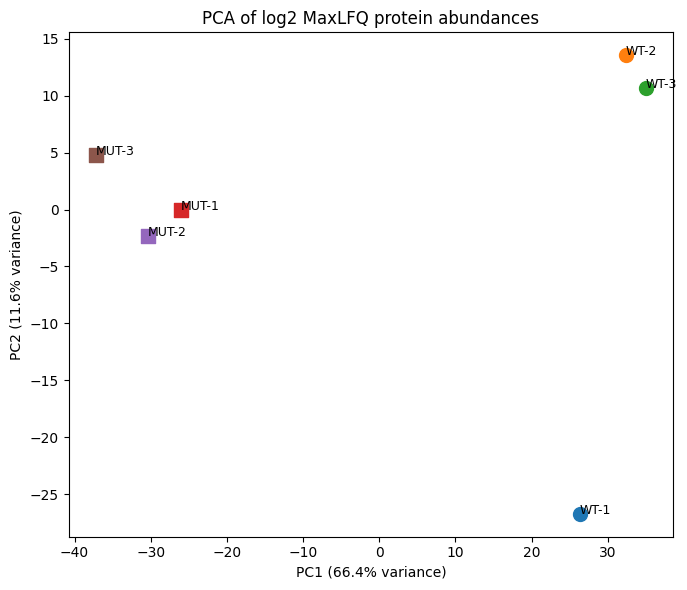

In [52]:
# Create the PCA plot
fig, ax = plt.subplots(figsize=(7, 6))

# Plot each sample individually
for sample, row in pca_df.iterrows():

    # Use one marker shape for WT and another for MUT
    marker = "o" if row["Condition"] == "IDHwt" else "s"

    ax.scatter(
        row["PC1"],
        row["PC2"],
        s=100,
        marker=marker,
        label=row["Condition"]
    )

    # Write the sample name next to its point
    ax.text(
        row["PC1"],
        row["PC2"],
        sample,
        fontsize=9
    )

# Axis labels include the amount of variation explained
ax.set_xlabel(f"PC1 ({explained[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.1f}% variance)")

ax.set_title("PCA of log2 MaxLFQ protein abundances")

plt.tight_layout()
plt.show()

In [53]:
pca_df

,PC1,PC2,Condition
sample,,,
WT-1,26.284836,-26.715173,IDHwt
WT-2,32.326899,13.542387,IDHwt
WT-3,34.981111,10.670520,IDHwt
MUT-1,-26.015184,-0.013874,IDHmut
MUT-2,-30.396188,-2.306941,IDHmut
MUT-3,-37.181474,4.823080,IDHmut


# Which proteins drive PC1?
* This is where PCA becomes biologically interesting.
* PCA assigns each of the 3,518 proteins a loading. A loading tells us how strongly that protein contributes to a principal component.

In [54]:
# Extract PC1 loadings
# PCA gives one loading for every protein
# pca.components_[0] = loadings for PC1

pc1_loadings = pca.components_[0]

print("Number of PC1 loadings:", len(pc1_loadings))


Number of PC1 loadings: 3518


In [57]:
# Get protein information for exactly the proteins used in PCA
pca_protein_info = protein_info.loc[log2_complete.index].copy()

# Add the PC1 loading for each protein
pca_protein_info["PC1_loading"] = pc1_loadings

# Look at the first few rows
pca_protein_info.head()

,Protein,Protein ID,Gene,Description,PC1_loading
14,sp|A0A075B6P5|KV228_HUMAN,A0A075B6P5,IGKV2-28,Immunoglobulin kappa variable 2-28,0.006290
20,sp|A0A0A0MRZ8|KVD11_HUMAN,A0A0A0MRZ8,IGKV3D-11,Immunoglobulin kappa variable 3D-11,0.009174
21,sp|A0A0A0MS15|HV349_HUMAN,A0A0A0MS15,IGHV3-49,Immunoglobulin heavy variable 3-49,0.014763
23,sp|A0A0B4J1V0|HV315_HUMAN,A0A0B4J1V0,IGHV3-15,Immunoglobulin heavy variable 3-15,0.013261
26,sp|A0A0B4J1X5|HV374_HUMAN,A0A0B4J1X5,IGHV3-74,Immunoglobulin heavy variable 3-74,0.018346


In [58]:
top_positive = (
    pca_protein_info
    .sort_values("PC1_loading", ascending=False)
    .head(10)
)

top_positive[["Gene", "Description", "PC1_loading"]]

,Gene,Description,PC1_loading
2243,CHI3L1,Chitinase-3-like protein 1,0.092363
1101,F13A1,Coagulation factor XIII A chain,0.080301
1181,COL1A1,Collagen alpha-1(I) chain,0.073658
1571,COL6A3,Collagen alpha-3(VI) chain,0.069849
1244,ANXA1,Annexin A1,0.066637
182,CLIC1,Chloride intracellular channel protein 1,0.063843
1293,MPO,Myeloperoxidase,0.063032
1391,COL1A2,Collagen alpha-2(I) chain,0.060939
1358,ANXA2,Annexin A2,0.060774
8134,EMILIN1,EMILIN-1,0.060142


In [60]:
top_negative = (
    pca_protein_info
    .sort_values("PC1_loading", ascending=True)
    .head(10)
)

top_negative[["Gene", "Description", "PC1_loading"]]

,Gene,Description,PC1_loading
5649,TNR,Tenascin-R,-0.084081
1528,HAPLN1,Hyaluronan and proteoglycan link protein 1,-0.073182
5954,BCAN,Brevican core protein,-0.067312
3922,STX1A,Syntaxin-1A,-0.060525
1929,OMG,Oligodendrocyte-myelin glycoprotein,-0.058506
1603,VCAN,Versican core protein,-0.057661
270,NCAN,Neurocan core protein,-0.057437
4699,NEGR1,Neuronal growth regulator 1,-0.056078
5640,NRGN,Neurogranin,-0.055567
2149,L1CAM,Neural cell adhesion molecule L1,-0.055058


In [61]:
pca_protein_info.to_csv(
    processed_dir / "pca_pc1_loadings.csv",
    index=False
)

In [62]:
pca_df.to_csv(
    processed_dir / "pca_sample_scores.csv"
)

In [63]:
# Columns belonging to each biological condition
wt_samples = ["WT-1", "WT-2", "WT-3"]
mut_samples = ["MUT-1", "MUT-2", "MUT-3"]

In [64]:
# Mean log2 abundance across the 3 WT replicates
wt_mean = log2_complete[wt_samples].mean(axis=1)

# Mean log2 abundance across the 3 MUT replicates
mut_mean = log2_complete[mut_samples].mean(axis=1)

In [65]:
# Calculate log2 fold change
# Positive value = higher in IDHmut
# Negative value = higher in IDHwt
log2fc = mut_mean - wt_mean

In [66]:
print("Minimum log2FC:", log2fc.min())
print("Maximum log2FC:", log2fc.max())

log2fc.head()

Minimum log2FC: -5.528384646493947
Maximum log2FC: 5.242652004906503


14   -0.205339
20   -0.535807
21   -0.819681
23   -0.690500
26   -1.032436
dtype: float64

## Perform the statistical test
* We will use a Welch's t-test.
* Why Welch rather than the ordinary Student t-test? Because Welch's test does not require WT and MUT to have exactly the same variance.

In [67]:
from scipy.stats import ttest_ind

In [68]:
# Convert WT and MUT parts of the matrix to arrays
wt_values = log2_complete[wt_samples].values
mut_values = log2_complete[mut_samples].values

# Perform one Welch t-test per protein
t_stat, p_values = ttest_ind(
    mut_values,
    wt_values,
    axis=1,
    equal_var=False
)

In [69]:
print("Number of tests:", len(p_values))
print("Smallest p-value:", p_values.min())

Number of tests: 3518
Smallest p-value: 5.4726346378305405e-06


In [70]:
# Correct for multiple testing
# If you perform 3,518 tests, some small p-values will occur just by chance.
# We therefore apply the Benjamini–Hochberg false-discovery-rate correction.
from statsmodels.stats.multitest import multipletests

In [71]:
# Benjamini-Hochberg FDR correction
reject, q_values, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="fdr_bh"
)

In [72]:
# Build the differential-abundance results table
# Now combine protein identity, fold change, and statistics.
# Get annotation for the exact 3518 proteins used in the test
diff = protein_info.loc[log2_complete.index].copy()

# Add quantitative/statistical results
diff["WT_mean"] = wt_mean
diff["MUT_mean"] = mut_mean
diff["log2FC"] = log2fc
diff["p_value"] = p_values
diff["q_value"] = q_values

In [73]:
# Statistical significance
significant = diff["q_value"] < 0.05

# At least 2-fold abundance difference
large_change = diff["log2FC"].abs() >= 1

# Must satisfy both criteria
diff["Significant"] = significant & large_change

In [74]:
print("Proteins tested:", len(diff))
print("q < 0.05:", significant.sum())
print("q < 0.05 and |log2FC| >= 1:", diff["Significant"].sum())

Proteins tested: 3518
q < 0.05: 3
q < 0.05 and |log2FC| >= 1: 3


In [75]:
mut_higher = (
    diff["Significant"] &
    (diff["log2FC"] > 0)
)

wt_higher = (
    diff["Significant"] &
    (diff["log2FC"] < 0)
)

print("Higher in IDHmut:", mut_higher.sum())
print("Higher in IDHwt:", wt_higher.sum())

Higher in IDHmut: 2
Higher in IDHwt: 1


In [76]:
# Look at the strongest proteins
# Higher in MUT:
diff.loc[mut_higher].sort_values(
    "log2FC",
    ascending=False
)[
    ["Gene", "Description", "log2FC", "p_value", "q_value"]
].head(15)

,Gene,Description,log2FC,p_value,q_value
2127,GDI1,Rab GDP dissociation inhibitor alpha,1.342397,0.000034,0.039333
7007,RAB18,Ras-related protein Rab-18,1.171852,0.000010,0.018176


In [77]:
# Higher in WT:
diff.loc[wt_higher].sort_values(
    "log2FC",
    ascending=True
)[
    ["Gene", "Description", "log2FC", "p_value", "q_value"]
].head(15)

,Gene,Description,log2FC,p_value,q_value
2769,MANF,Mesencephalic astrocyte-derived neurotrophic f...,-1.229291,0.000005,0.018176


In [78]:
diff.to_csv(
    processed_dir / "differential_abundance_IDHmut_vs_IDHwt.csv",
    index=False
)

In [79]:
# Convert q-values into -log10(q)
# Smaller q-value -> larger value on the volcano plot

diff["minus_log10_q"] = -np.log10(diff["q_value"])

diff[
    ["Gene", "log2FC", "q_value", "minus_log10_q"]
].head()

,Gene,log2FC,q_value,minus_log10_q
14,IGKV2-28,-0.205339,0.897027,0.047194
20,IGKV3D-11,-0.535807,0.398108,0.399999
21,IGHV3-49,-0.819681,0.531123,0.274805
23,IGHV3-15,-0.690500,0.591708,0.227893
26,IGHV3-74,-1.032436,0.366979,0.435359


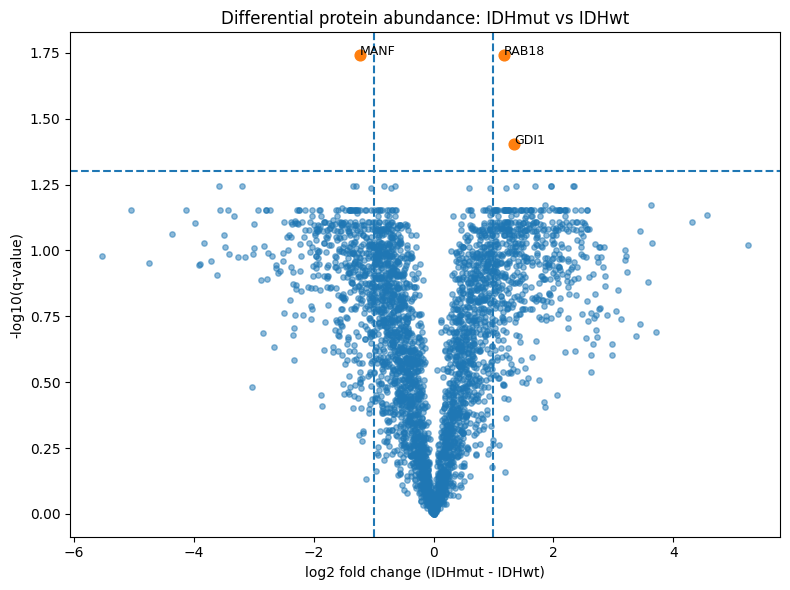

In [80]:
fig, ax = plt.subplots(figsize=(8, 6))

# First plot all proteins
ax.scatter(
    diff["log2FC"],
    diff["minus_log10_q"],
    s=15,
    alpha=0.5
)

# Select significant proteins
sig = diff[
    (diff["q_value"] < 0.05) &
    (diff["log2FC"].abs() >= 1)
]

# Plot significant proteins again so they stand out
ax.scatter(
    sig["log2FC"],
    sig["minus_log10_q"],
    s=60
)

# Add fold-change thresholds
ax.axvline(-1, linestyle="--")
ax.axvline(1, linestyle="--")

# q = 0.05 threshold
ax.axhline(
    -np.log10(0.05),
    linestyle="--"
)

ax.set_xlabel("log2 fold change (IDHmut - IDHwt)")
ax.set_ylabel("-log10(q-value)")
ax.set_title("Differential protein abundance: IDHmut vs IDHwt")

# Label significant genes
for _, row in sig.iterrows():
    ax.text(
        row["log2FC"],
        row["minus_log10_q"],
        row["Gene"],
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [81]:
fig.savefig(
    "../results/processed/volcano_IDHmut_vs_IDHwt.png",
    dpi=300,
    bbox_inches="tight"
)

In [82]:
# Select statistically significant proteins
final_hits = diff.loc[
    (diff["q_value"] < 0.05) &
    (diff["log2FC"].abs() >= 1)
].copy()

# Sort from smallest q-value to largest
final_hits = final_hits.sort_values("q_value")

final_hits[
    ["Gene", "Description", "WT_mean", "MUT_mean",
     "log2FC", "p_value", "q_value"]
]

,Gene,Description,WT_mean,MUT_mean,log2FC,p_value,q_value
2769,MANF,Mesencephalic astrocyte-derived neurotrophic f...,27.025203,25.795912,-1.229291,0.000005,0.018176
7007,RAB18,Ras-related protein Rab-18,27.039146,28.210998,1.171852,0.000010,0.018176
2127,GDI1,Rab GDP dissociation inhibitor alpha,30.311181,31.653578,1.342397,0.000034,0.039333


## Analysis summary

Six DDA LC-MS/MS runs comprising three IDHwt and three IDHmut
samples were processed using the FragPipe LFQ-MBR workflow.

Protein identification was performed using MSFragger followed by
rescoring and FDR filtering with the FragPipe validation pipeline.
Label-free quantification was performed using IonQuant with
match-between-runs and MaxLFQ quantification.

The combined FragPipe output contained 8,181 protein groups.
After removal of six contaminants, 8,175 protein groups remained.
Proteins quantified in at least two of three replicates in either
condition were retained, resulting in 6,233 proteins.

For complete-case multivariate and statistical analysis, 3,518
proteins quantified in all six samples were used.

Sample intensity distributions were comparable across all six runs.
Within-condition Pearson correlations were high, ranging from
0.920–0.933 for IDHwt and 0.952–0.957 for IDHmut samples.

PCA showed clear separation between IDHwt and IDHmut samples.
PC1 accounted for 66.4% of total variance and PC2 accounted for
11.6%, giving 78.0% cumulative variance explained.

Differential abundance analysis using Welch's t-test followed by
Benjamini-Hochberg FDR correction identified three proteins with
q < 0.05 and |log2FC| >= 1.

GDI1 and RAB18 showed higher abundance in IDHmut samples, whereas
MANF showed higher abundance in IDHwt samples.

Because only three biological replicates were available per condition,
the differential-abundance results should be interpreted as an
exploratory analysis rather than definitive biomarker evidence.